<a href="https://colab.research.google.com/github/iman-ch/C-DSA/blob/main/03_contract_nli.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

notebook connects previous model that deals with regular english to contract language.
- zero-shot evaluation: how it performs on task it was not trained for
- fine tune on contractnli
- measure after to compare before and after

## 1. Setup

### **1.1** install dependencies

In [2]:
!pip install -q transformers datasets mlflow scikit-learn
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### **1.2** imports and configurations

In [3]:
import os, time
from collections import Counter
import numpy as np
import pandas as pd
import torch
import mlflow
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding)
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from tqdm.auto import tqdm

device = torch.device("cuda")
PROJ_DIR = "/content/drive/MyDrive/doc-contradiction-detector"

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
mlflow.set_tracking_uri(f"file:{PROJ_DIR}/mlruns")
mlflow.set_experiment("contractnli")

MNLI_LABELS = ["entailment", "neutral", "contradiction"]
BEST_GENERAL = f"{PROJ_DIR}/models/lr3e-05_len128_n100k" # best run from notebook 2

2026/10/10 20:37:00 INFO mlflow.tracking.fluent: Experiment with name 'contractnli' does not exist. Creating a new experiment.


### **1.3** functions from notebook 2

#### **1.3.1** train one epoch

In [4]:
def train_one_epoch(model, loader, optimizer, loss_fn, scaler):
  model.train()
  total_loss = 0
  for batch in tqdm(loader, desc="train", leave=False):
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = batch["labels"].to(device)

    optimizer.zero_grad() # zero
    with torch.autocast(device_type="cuda", dtype=torch.float16):
      logits = model(input_ids=input_ids, attention_mask=attention_mask).logits  # fwd
      loss = loss_fn(logits, labels) # loss
    scaler.scale(loss).backward() # bkwd
    scaler.step(optimizer) # step
    scaler.update()

    total_loss += loss.item()
  return total_loss / len(loader)



#### **1.3.2** evaluate

In [5]:
def evaluate(model, loader):
  model.eval()
  all_preds, all_labels = [], []
  with torch.no_grad():
    for batch in loader:
      input_ids = batch["input_ids"].to(device)
      attention_mask = batch["attention_mask"].to(device)
      with torch.autocast(device_type="cuda", dtype=torch.float16):
          logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
      all_preds.extend(logits.argmax(dim=-1).cpu().tolist())
      all_labels.extend(batch["labels"].tolist())
  acc = accuracy_score(all_labels, all_preds)
  f1s = f1_score(all_labels, all_preds, average=None)

  return acc, f1s

## 2. ContractNLI Loading, Inspection

### **2.1** loading dataset

In [7]:
cnli = load_dataset("kiddothe2b/contract-nli", data_dir="contractnli_a", revision="refs/convert/parquet")
print(cnli)

cnli_names = cnli["train"].features["label"].names
print(cnli_names)

0000.parquet:   0%|          | 0.00/796k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/114k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/213k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 6819
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 978
    })
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 1991
    })
})
['contradiction', 'entailment', 'neutral']


### **2.2** exploring dataset

In [8]:
print(Counter(cnli["train"]["label"])) # class balance

ex = cnli["train"][0] # one raw example
print("PREMISE:", ex["premise"][:500])
print("HYPOTHESIS:", ex["hypothesis"])
print("LABEL:", cnli_names[ex["label"]])

for h, n in Counter(cnli["train"]["hypothesis"]).most_common(20):
  print(n, h) # what column contains

Counter({1: 3195, 2: 2820, 0: 804})
PREMISE: 2.3 Provided that the Recipient has a written agreement with the following persons or entities requiring them to treat the Confidential Information in accordance with this Agreement, the Recipient may disclose the Confidential Information to: 2.3.1  Any other party with the Discloser’s prior written consent; and 2.3.2 the Recipient’s employees, officials, representatives and agents who have a strict need to know the contents of the Confidential Information, and employees, officials, representati
HYPOTHESIS: Receiving Party shall not reverse engineer any objects which embody Disclosing Party's Confidential Information.
LABEL: neutral
422 Receiving Party shall not reverse engineer any objects which embody Disclosing Party's Confidential Information.
417 Receiving Party may retain some Confidential Information even after the return or destruction of Confidential Information.
417 Receiving Party may create a copy of some Confidential Information

- Imbalanced labels: contradiction is only 12% of training pairs (804 of 6,819) vs. ~33% in MultiNLI. Accuracy can hide missed contradictions, will try contradiction F1 and test class weights
- 17 fixed hypothesis: model learns how NDAs phrase a small set of recurring topics

### **2.3** token lengths

In [9]:
tokenizer = AutoTokenizer.from_pretrained(BEST_GENERAL)

sample = cnli["train"].shuffle(seed=42).select(range(1000))
lengths = [ len(tokenizer(p, h)["input_ids"])
            for p, h in zip(sample["premise"], sample["hypothesis"])  ]
print(np.percentile(lengths, [50, 90, 95, 99]))
print("Share over 256:", np.mean(np.array(lengths) > 256))

[110.   262.   333.05 482.04]
Share over 256: 0.108


In [10]:
MAX_LEN = 384 # smallest of 256, 384, 512 that covers 95% of examples

## 3. Align Labels

### **3.1** remap labels

base model position 2 means contradiction, but cnli labels it differently. remapping to make sure everything is aligned.

In [11]:
mapping = {i: MNLI_LABELS.index(name) for i, name in enumerate(cnli_names)}
print(mapping) # expect {0: 2, 1: 0, 2: 1}

def remap(example):
  return {"mnli_label": mapping[example["label"]]}

cnli = cnli.map(remap).remove_columns("label").rename_column("mnli_label", "label")
print(Counter(cnli["train"]["label"]))

{0: 2, 1: 0, 2: 1}


Map:   0%|          | 0/6819 [00:00<?, ? examples/s]

Map:   0%|          | 0/978 [00:00<?, ? examples/s]

Map:   0%|          | 0/1991 [00:00<?, ? examples/s]

Counter({0: 3195, 1: 2820, 2: 804})


## 4. Data Pipeline

### **4.1** dataset to DataLoader

In notebook 2, tokenize and batch steps lived in run_experiment. Need them standalone.

In [13]:
def make_loader(ds, tokenizer, max_length, batch_size, shuffle=False, text_a="premise", text_b="hypothesis"):

  def tok(batch):
    return tokenizer(batch[text_a], batch[text_b], truncation="only_first", max_length=max_length)

  keep = ["input_ids", "attention_mask", "label"]
  ds = ds.map(tok, batched=True)
  ds = ds.remove_columns([c for c in ds.column_names if c not in keep])
  collator = DataCollatorWithPadding(tokenizer)

  return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, collate_fn=collator)

In [14]:
train_loader = make_loader(cnli["train"], tokenizer, MAX_LEN, batch_size=16, shuffle=True)
val_loader = make_loader(cnli["validation"], tokenizer, MAX_LEN, batch_size=64)
test_loader = make_loader(cnli["test"], tokenizer, MAX_LEN, batch_size=64)

batch = next(iter(train_loader))
print(batch["input_ids"].shape, batch.keys())

Map:   0%|          | 0/6819 [00:00<?, ? examples/s]

Map:   0%|          | 0/978 [00:00<?, ? examples/s]

Map:   0%|          | 0/1991 [00:00<?, ? examples/s]

torch.Size([16, 384]) KeysView({'input_ids': tensor([[  101,  1017,  1012,  ...,     0,     0,     0],
        [  101,  1018,  1012,  ...,     0,     0,     0],
        [  101,  1037,  4909,  ...,     0,     0,     0],
        ...,
        [  101,  1006,  1039,  ...,     0,     0,     0],
        [  101,  1999,  2804,  ...,  3820,  1012,   102],
        [  101,  6951, 28049,  ...,     0,     0,     0]]), 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        ...,
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 0, 0, 0]]), 'labels': tensor([2, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 2, 1, 0, 0, 0])})


## 5. Zero-shot Evaluation

### **5.1** load a saved model and score it

In [15]:
model = AutoModelForSequenceClassification.from_pretrained(BEST_GENERAL).to(device)

zs_acc, zs_f1 = evaluate(model, test_loader)
print(f"Zero-shot test accuracy: {zs_acc:.2%}")
for name, f in zip(MNLI_LABELS, zs_f1):
    print(f"  F1 {name}: {f:.3f}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Zero-shot test accuracy: 40.53%
  F1 entailment: 0.454
  F1 neutral: 0.428
  F1 contradiction: 0.271


### **5.2** confusion matrix

In [20]:
def get_preds(model, loader):
  model.eval()
  preds, labels = [], []
  with torch.no_grad():
    for batch in loader:
      with torch.autocast(device_type="cuda", dtype=torch.float16):
        logits = model(input_ids=batch["input_ids"].to(device), attention_mask=batch["attention_mask"].to(device)).logits
      preds.extend(logits.argmax(dim=-1).cpu().tolist())
      labels.extend(batch["labels"].tolist())
  return labels, preds

In [21]:
y_true, y_pred = get_preds(model, test_loader)
cm = confusion_matrix(y_true, y_pred)
print(pd.DataFrame(cm, index=[f"true_{n}" for n in MNLI_LABELS], columns=[f"pred_{n}" for n in MNLI_LABELS]))

                    pred_entailment  pred_neutral  pred_contradiction
true_entailment                 343           329                 206
true_neutral                    251           352                 300
true_contradiction               39            59                 112


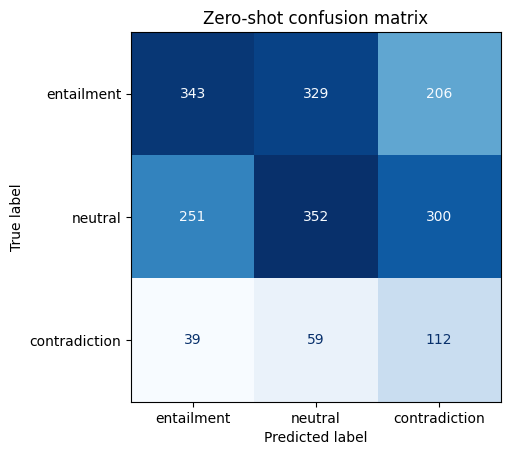

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=MNLI_LABELS)
disp.plot(cmap="Blues", colorbar=False)
plt.title("Zero-shot confusion matrix")
plt.show()

## 6. Fine-Tuning on Contracts

### **6.1** class weights for imbalanced data

In [24]:
counts = Counter(cnli["train"]["label"])
total = sum(counts.values())
weights = torch.tensor([total / (3 * counts[i]) for i in range(3)], dtype=torch.float).to(device)
print(dict(zip(MNLI_LABELS, weights.tolist())))

{'entailment': 0.7114241123199463, 'neutral': 0.8060283660888672, 'contradiction': 2.8271143436431885}


### **6.2** fine tune, keep best epoch

In [26]:
def fine_tune(model, tokenizer, train_loader, val_loader, loss_fn,
              lr, epochs, save_dir, run_name, watch_class=2):
  optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
  scaler = torch.amp.GradScaler("cuda")
  best = -1

  with mlflow.start_run(run_name=run_name):
    mlflow.log_params({"lr": lr, "epochs": epochs, "weighted": loss_fn.weight is not None})
    for epoch in range(epochs):
      loss = train_one_epoch(model, train_loader, optimizer, loss_fn, scaler)
      acc, f1s = evaluate(model, val_loader)
      mlflow.log_metric("train_loss", loss, step=epoch)
      mlflow.log_metric("val_accuracy", acc, step=epoch)
      mlflow.log_metric("val_f1_watch", f1s[watch_class], step=epoch)
      print(f"epoch {epoch + 1} | loss {loss:.4f} | acc {acc:.2%} | "f"watched F1 {f1s[watch_class]:.3f}")
      if f1s[watch_class] > best:
        best = f1s[watch_class]
        model.save_pretrained(save_dir)
        tokenizer.save_pretrained(save_dir)
        print("  saved (new best)")
    mlflow.log_metric("best_val_f1_watch", best)
  return best

In [27]:
# Run A: no class weights
model = AutoModelForSequenceClassification.from_pretrained(BEST_GENERAL).to(device)
best_a = fine_tune(model, tokenizer, train_loader, val_loader,
                   loss_fn=torch.nn.CrossEntropyLoss(),
                   lr=2e-5, epochs=3,
                   save_dir=f"{PROJ_DIR}/models/contractnli_unweighted",
                   run_name="contractnli_unweighted")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

train:   0%|          | 0/427 [00:00<?, ?it/s]

epoch 1 | loss 0.6060 | acc 80.88% | watched F1 0.693


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  saved (new best)


...

epoch 2 | loss 0.4241 | acc 82.00% | watched F1 0.670


train:   0%|          | 0/427 [00:00<?, ?it/s]

epoch 3 | loss 0.3512 | acc 83.13% | watched F1 0.723


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  saved (new best)


In [28]:
# Run B: class weights
model = AutoModelForSequenceClassification.from_pretrained(BEST_GENERAL).to(device)
best_b = fine_tune(model, tokenizer, train_loader, val_loader,
                   loss_fn=torch.nn.CrossEntropyLoss(weight=weights),
                   lr=2e-5, epochs=3,
                   save_dir=f"{PROJ_DIR}/models/contractnli_weighted",
                   run_name="contractnli_weighted")
print("Best val contradiction F1, unweighted vs weighted:", best_a, best_b)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

train:   0%|          | 0/427 [00:00<?, ?it/s]

epoch 1 | loss 0.6193 | acc 77.40% | watched F1 0.622


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  saved (new best)


...

epoch 2 | loss 0.4339 | acc 82.41% | watched F1 0.709


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  saved (new best)


train:   0%|          | 0/427 [00:00<?, ?it/s]

epoch 3 | loss 0.3447 | acc 82.41% | watched F1 0.703
Best val contradiction F1, unweighted vs weighted: 0.7227722772277227 0.7090909090909091


Both runs jumped to 80%+ validation accuracy within one epoch. Unweighted reached the best contradiction F1 (0.723, epoch 3) vs. weighted (0.709, epoch 2). The difference is small and minimal amount of noise, so the simpler unweighted model is kept.

Class weights didn’t help, possibly because 12% contradictions is imbalanced but not extreme, and fine-tuning alone was enough for the model to learn the class.

In [29]:
LEGAL_MODEL = f"{PROJ_DIR}/models/contractnli_unweighted"

## 7. Test Evaluation

### **7.1** final evaluation

In [30]:
legal = AutoModelForSequenceClassification.from_pretrained(LEGAL_MODEL).to(device)
ft_acc, ft_f1 = evaluate(legal, test_loader)

y_true, y_pred = get_preds(legal, test_loader)
print(pd.DataFrame(confusion_matrix(y_true, y_pred),
                   index=[f"true_{n}" for n in MNLI_LABELS],
                   columns=[f"pred_{n}" for n in MNLI_LABELS]))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

                    pred_entailment  pred_neutral  pred_contradiction
true_entailment                 783            70                  25
true_neutral                    178           694                  31
true_contradiction               33            14                 163


### **7.2** before/after

In [31]:
results = pd.DataFrame({
    "Model": ["General (zero-shot)", "Fine-tuned on ContractNLI"],
    "Test accuracy": [zs_acc, ft_acc],
    "F1 entailment": [zs_f1[0], ft_f1[0]],
    "F1 neutral": [zs_f1[1], ft_f1[1]],
    "F1 contradiction": [zs_f1[2], ft_f1[2]],
}).round(3)
results

,Model,Test accuracy,F1 entailment,F1 neutral,F1 contradiction
0,General (zero-shot),0.405,0.454,0.428,0.271
1,Fine-tuned on ContractNLI,0.824,0.837,0.826,0.760


Improved as expected, fine tuning on ContractNLI raised test accuracy from 0.405 to 0.824 and contradiction F1 from 0.271 to 0.760
 over the zero-shot baseline. I evaluated on the test set only once, after selecting the model on validation, so the result is an unbiased estimate of performance on unseen contracts.

## 8. Results

### **8.1** predictions in table form

In [32]:
def predict_dataset(model, ds, tokenizer, max_length, label_names, batch_size=64):
  loader = make_loader(ds, tokenizer, max_length, batch_size)   # shuffle=False
  model.eval()
  probs = []
  with torch.no_grad():
    for batch in loader:
      with torch.autocast(device_type="cuda", dtype=torch.float16):
        logits = model(input_ids=batch["input_ids"].to(device),attention_mask=batch["attention_mask"].to(device)).logits
      probs.append(logits.float().softmax(dim=-1).cpu())
  probs = torch.cat(probs).numpy()

  df = ds.to_pandas()
  df["true"] = [label_names[i] for i in df["label"]]
  df["pred"] = [label_names[i] for i in probs.argmax(axis=1)]
  df["confidence"] = probs.max(axis=1)
  for i, name in enumerate(label_names):
      df[f"p_{name}"] = probs[:, i]
  df["correct"] = df["true"] == df["pred"]
  return df

In [33]:
preds = predict_dataset(legal, cnli["test"], tokenizer, MAX_LEN, MNLI_LABELS)

os.makedirs(f"{PROJ_DIR}/results", exist_ok=True)
preds.to_csv(f"{PROJ_DIR}/results/contractnli_test_predictions.csv", index=False)

print(preds["correct"].mean()) # should match ft_acc
preds[~preds["correct"]].head()

0.8237066800602713


,premise,hypothesis,label,true,pred,confidence,p_entailment,p_neutral,p_contradiction,correct
3,In the event that a receiving party or its Ass...,Receiving Party shall not disclose the fact th...,1,neutral,entailment,0.741204,0.741204,0.251444,0.007352,False
5,"For purposes of this Agreement, ""Confidential ...",All Confidential Information shall be expressl...,2,contradiction,neutral,0.929848,0.025194,0.929848,0.044958,False
9,“Confidential Information” means any informati...,Confidential Information may include verbally ...,1,neutral,entailment,0.919646,0.919646,0.074756,0.005598,False
12,e. Return of Information. on a Party's request...,Receiving Party may create a copy of some Conf...,0,entailment,neutral,0.584037,0.262188,0.584037,0.153775,False
25,Recipient will not disclose or permit access t...,Receiving Party may share some Confidential In...,2,contradiction,entailment,0.934450,0.934450,0.062842,0.002708,False


In [37]:
results.to_csv(f"{PROJ_DIR}/results/contractnli_before_after.csv", index=False)

### **8.2** upload model to hugging face hub

In [36]:
from huggingface_hub import notebook_login
notebook_login()

legal = AutoModelForSequenceClassification.from_pretrained(LEGAL_MODEL)
legal.config.id2label = {0: "entailment", 1: "neutral", 2: "contradiction"}
legal.config.label2id = {"entailment": 0, "neutral": 1, "contradiction": 2}
legal.push_to_hub("imanxch/distilbert-contractnli")
tokenizer.push_to_hub("imanxch/distilbert-contractnli")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/5.02k [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...ainlhxx/model.safetensors:   3%|2         | 7.98MB /  268MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/imanxch/distilbert-contractnli/commit/124bdcede741d1a3fd999512a7813269e9c0c29a', commit_message='Upload tokenizer', commit_description='', oid='124bdcede741d1a3fd999512a7813269e9c0c29a', pr_url=None, repo_url=RepoUrl('https://huggingface.co/imanxch/distilbert-contractnli', endpoint='https://huggingface.co', repo_type='model', repo_id='imanxch/distilbert-contractnli'), pr_revision=None, pr_num=None)